# 04 · Verification

**Question:** do the findings of `03_event_effect` survive other reasonable choices?

The main model from notebook 03 (Step 3) is re-run under different choices, and the event effects are compared. A result that moves a lot with a small change is not trustworthy;
a result that stays put is.

| Check | What changes |
|---|---|
| 1. Main model | Rebuilt from scratch here; must match notebook 03 |
| 2. Event windows | 1 or 3 hours before and after the event; games of 2 or 4 hours instead of 3 |
| 3. Model choices | each weekday × hour, month × year, a different distribution, no controls |
| 4. Which hours are used | without winter, January 2025, holidays, snow, multi-event days; each year; weekdays or weekends only |
| 5. Fake events | all events moved to random days with no event, 200 times, and the model refitted |
| 6. Summary | what holds, what does not |

Rate ratios read as before: 1.00 = no difference, 1.10 = 10% more incidents, 0.90 = 10% fewer.

## 0. Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf

# Works whether the kernel starts in notebooks/ or in the project root
PROCESSED = next(p for p in (Path("../data/processed"), Path("data/processed")) if p.exists())

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.titleweight"] = "bold"
pd.set_option("display.width", 160)

GROUP_OF_TYPE = {"mlb": "mlb", "nhl": "nhl", "nba": "nba", "mls": "mls", "world_cup": "other", "parade": "other", "festival": "other", "road_race": "other"}
EVENT_FLAGS = {"win_mlb": "Baseball", "win_nhl": "Hockey", "win_nba": "Basketball", "win_mls": "Toronto FC", "win_other": "Other events"}
GROUP_COLORS = {"Baseball": "#2e86c1", "Hockey": "#1f3a5f", "Basketball": "#c0392b", "Toronto FC": "#6aa84f", "Other events": "#8e7cc3"}
CODING_CHANGE = pd.Timestamp("2026-04-01")

events = pd.read_csv(PROCESSED / "events.csv", parse_dates=["date", "start", "end", "window_start", "window_end"])
hourly = pd.read_csv(PROCESSED / "hourly.csv", parse_dates=["datetime", "date"])
daily = pd.read_csv(PROCESSED / "daily.csv", parse_dates=["date"])
incidents = pd.read_csv(PROCESSED / "incidents.csv", parse_dates=["datetime"], usecols=["datetime", "min_delay"])
timed = events.dropna(subset=["start"]).drop_duplicates("event_id").copy()
timed["group"] = timed["event_type"].map(GROUP_OF_TYPE)
print(f"{len(timed)} events with a start time | {len(hourly):,} hours")

353 events with a start time | 15,312 hours


## 1. The model table, with adjustable event windows

`build_table` rebuilds the modelling table of notebook 03 (Step 1) for any window rule:
`before` and `after` are the hours added before the start and after the end, and `game_hours` is the assumed length of games with no end time. The default is 2, 2 and 3, as in notebook 03.

In [2]:
long_delays = (incidents["min_delay"] > 30).groupby(incidents["datetime"].dt.floor("h")).sum()
BASE = hourly[["datetime", "date", "hour", "weekday", "is_weekend", "month", "year", "n_incidents", "n_diversion", "delay_min_total"]].rename(columns={"delay_min_total": "delay_minutes"})
BASE["n_long_delays"] = BASE["datetime"].map(long_delays).fillna(0).astype(int)
day_ctrl = daily[["date", "is_holiday", "temp_mean_c", "rain_mm", "snow_cm", "snow_3d_cm", "n_events"]]
BASE = BASE.merge(day_ctrl, on="date", how="left", validate="many_to_one")
BASE["is_holiday"] = BASE["is_holiday"].astype(int)
BASE["multi_event_day"] = (BASE["n_events"] >= 2).astype(int)
BASE["heavy_rain"] = (BASE["rain_mm"] >= 10).astype(int)
BASE["snow_day"] = (BASE["snow_cm"] > 0).astype(int)
BASE["snow3_over5"] = (BASE["snow_3d_cm"] > 5).astype(int)
BASE["snowy"] = BASE["snow_3d_cm"] > 2
BASE["temp_band"] = pd.cut(BASE["temp_mean_c"], [-40, -10, 0, 10, 20, 25, 40], labels=["below -10", "-10 to 0", "0 to 10", "10 to 20", "20 to 25", "above 25"]).astype(str)
BASE["weekday_type"] = np.where(BASE["is_weekend"], "weekend", "weekday")
BASE["slot"] = BASE["weekday_type"] + "_" + BASE["hour"].astype(str)
BASE["weekday_slot"] = BASE["weekday"] + "_" + BASE["hour"].astype(str)
BASE["period"] = BASE["date"].dt.to_period("M").astype(str)
BASE["after_coding_change"] = (BASE["date"] >= CODING_CHANGE).astype(int)
BASE["evening_date"] = (BASE["datetime"] - pd.Timedelta(hours=6)).dt.normalize()
BASE["in_scope"] = (BASE["hour"] >= 11) | (BASE["hour"] == 0)


def window_hours(before=2, after=2, game_hours=3):
    """One row per event-hour: (event_id, group, datetime, offset from the start hour)."""
    rows = []
    for r in timed.itertuples():
        end = r.end if pd.notna(r.end) else r.start + pd.Timedelta(hours=game_hours)
        for hour in pd.date_range((r.start - pd.Timedelta(hours=before)).floor("h"), end + pd.Timedelta(hours=after), freq="h", inclusive="left"):
            rows.append((r.event_id, r.group, hour, int((hour - r.start.floor("h")) / pd.Timedelta(hours=1))))
    return pd.DataFrame(rows, columns=["event_id", "group", "datetime", "offset"])


def build_table(before=2, after=2, game_hours=3):
    wh = window_hours(before, after, game_hours)
    flags = pd.crosstab(wh["datetime"], wh["group"]).gt(0).astype(int).add_prefix("win_").reset_index()
    table = BASE.merge(flags, on="datetime", how="left")
    for col in EVENT_FLAGS:
        table[col] = table.get(col, 0)
        table[col] = table[col].fillna(0).astype(int)
    table["in_event_window"] = (table[list(EVENT_FLAGS)].sum(axis=1) > 0).astype(int)
    return table[table["in_scope"]].reset_index(drop=True)


main_table = build_table()
print(f"{len(main_table):,} hours | event-window hours: {int(main_table['in_event_window'].sum()):,} | by group: "
      f"{ {EVENT_FLAGS[c]: int(main_table[c].sum()) for c in EVENT_FLAGS} }")

8,932 hours | event-window hours: 2,519 | by group: {'Baseball': 1366, 'Hockey': 506, 'Basketball': 525, 'Toronto FC': 239, 'Other events': 93}


### 1.1 Model functions and the main model (must match notebook 03)

In [3]:
EVENTS_RHS = " + ".join(EVENT_FLAGS)
TEMP = "C(temp_band, Treatment('10 to 20'))"
RHS_MAIN = f"C(slot) + C(month) + is_holiday + snow_day + snow3_over5 + {TEMP} + heavy_rain + after_coding_change + multi_event_day"


def drop_constant_terms(data, rhs):
    """Remove yes/no controls that never vary in a subset (they cannot be estimated)."""
    for term in ["is_holiday", "snow_day", "snow3_over5", "heavy_rain", "after_coding_change", "multi_event_day"]:
        if data[term].nunique() < 2:
            rhs = rhs.replace(f" + {term}", "")
    return rhs


def fit_model(data, rhs=RHS_MAIN, outcome="n_incidents", family="poisson"):
    """Poisson (or negative binomial) regression with standard errors clustered by evening."""
    rhs = drop_constant_terms(data, rhs)
    groups = pd.factorize(data["evening_date"])[0]
    fam = sm.families.Poisson()
    if family == "negbin":
        first = smf.glm(f"{outcome} ~ {EVENTS_RHS} + {rhs}", data=data, family=sm.families.Poisson()).fit()
        mu = first.fittedvalues
        alpha = max(float((((data[outcome] - mu) ** 2 - mu) / mu ** 2).mean()), 1e-3)
        fam = sm.families.NegativeBinomial(alpha=alpha)
    return smf.glm(f"{outcome} ~ {EVENTS_RHS} + {rhs}", data=data, family=fam).fit(cov_type="cluster", cov_kwds={"groups": groups})


def event_effects(res):
    ci = res.conf_int()
    t = pd.DataFrame({"rate_ratio": np.exp(res.params), "lo": np.exp(ci[0]), "hi": np.exp(ci[1])}).loc[list(EVENT_FLAGS)]
    return t.rename(index=EVENT_FLAGS)


main_effects = event_effects(fit_model(main_table))
main_effects.round(3)

,rate_ratio,lo,hi
Baseball,1.031,0.983,1.081
Hockey,0.963,0.886,1.047
Basketball,0.911,0.836,0.992
Toronto FC,1.087,0.999,1.182
Other events,0.953,0.837,1.084


**Check against notebook 03:** the rate ratios above should equal the main model there
(baseball 1.031, hockey 0.963, basketball 0.911, Toronto FC 1.087, other events 0.953).

In [4]:
expected_main = {"Baseball": 1.031, "Hockey": 0.963, "Basketball": 0.911, "Toronto FC": 1.087, "Other events": 0.953}
assert all(abs(main_effects.loc[k, "rate_ratio"] - v) < 0.002 for k, v in expected_main.items()), "does not match notebook 03"
print("The rebuilt main model matches notebook 03")

The rebuilt main model matches notebook 03


## 2. Different event windows
The window is a choice. Here the hours added before the start and after the end are changed (1, 2 or 3), and games are assumed to last 2, 3 or 4 hours.

,Baseball,Hockey,Basketball,Toronto FC,Other events
main,1.031,0.963,0.911,1.087,0.953
"window: 1 h before, 1 h after",1.030,0.967,0.896,1.059,0.954
"window: 3 h before, 3 h after",1.025,0.962,0.932,1.107,0.989
"window: 0 h before, 0 h after (game only)",1.044,0.954,0.881,1.012,0.943
games last 2 hours,1.021,0.961,0.899,1.091,0.970
games last 4 hours,1.033,0.957,0.912,1.101,0.954


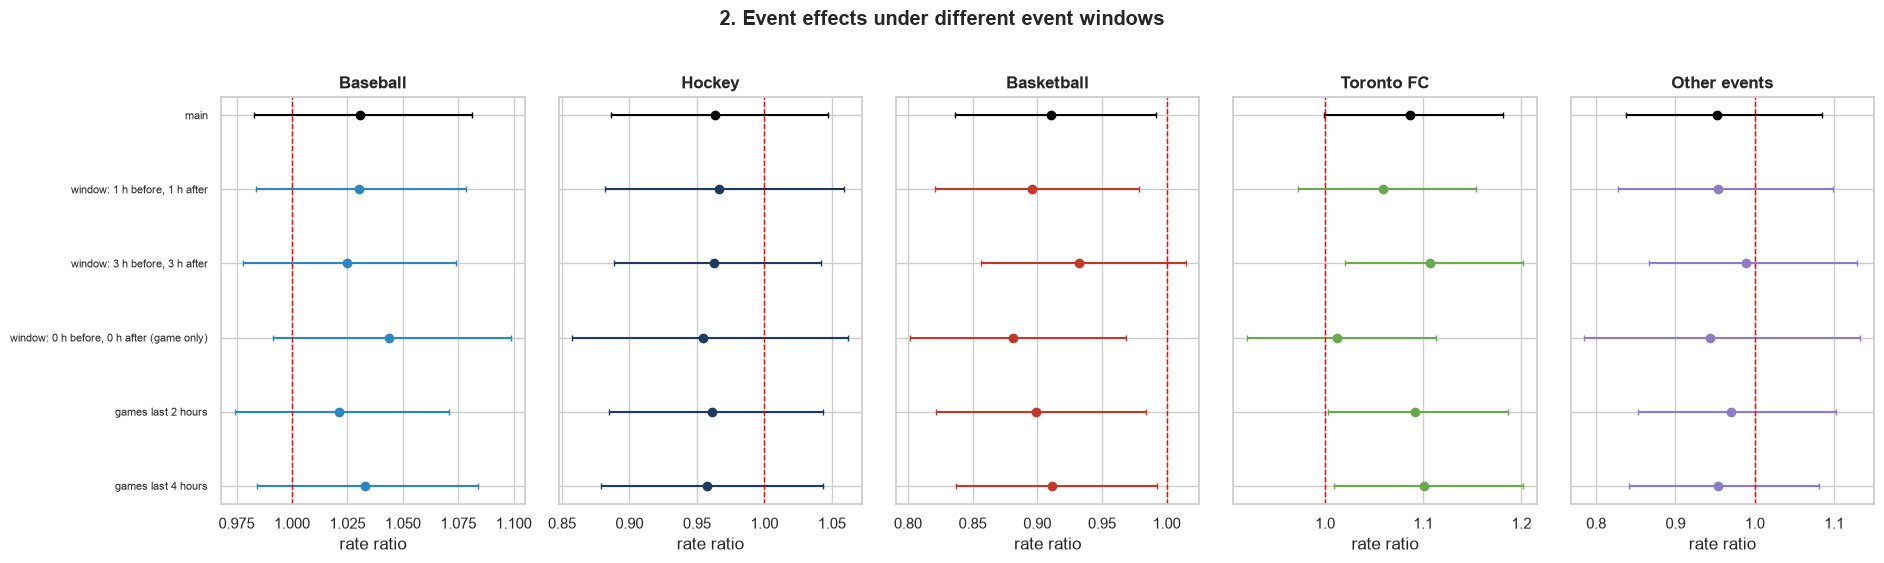

In [5]:
RESULTS = {"main": main_effects}   # collected for the summary in section 6
window_variants = {
    "window: 1 h before, 1 h after": dict(before=1, after=1),
    "window: 3 h before, 3 h after": dict(before=3, after=3),
    "window: 0 h before, 0 h after (game only)": dict(before=0, after=0),
    "games last 2 hours": dict(game_hours=2),
    "games last 4 hours": dict(game_hours=4),
}
for name, kwargs in window_variants.items():
    RESULTS[name] = event_effects(fit_model(build_table(**kwargs)))
window_table = pd.DataFrame({name: RESULTS[name]["rate_ratio"] for name in ["main"] + list(window_variants)}).T


def plot_checks(names, title):
    """One panel per event group: the rate ratio and interval under each check."""
    fig, axes = plt.subplots(1, 5, figsize=(19, 0.55 * len(names) + 2.2), sharey=True)
    ypos = np.arange(len(names))[::-1]
    for ax, group in zip(axes, EVENT_FLAGS.values()):
        for yi, name in zip(ypos, names):
            row = RESULTS[name].loc[group]
            ax.errorbar(row["rate_ratio"], yi, xerr=[[row["rate_ratio"] - row["lo"]], [row["hi"] - row["rate_ratio"]]], fmt="o", color=GROUP_COLORS[group] if name != "main" else "black", capsize=2)
        ax.axvline(1, color="red", ls="--", lw=1)
        ax.set(title=group, xlabel="rate ratio")
    axes[0].set_yticks(ypos)
    axes[0].set_yticklabels(names, fontsize=8)
    fig.suptitle(title, fontweight="bold", y=1.02)
    plt.tight_layout()


plot_checks(["main"] + list(window_variants), "2. Event effects under different event windows")
window_table.round(3)

**How to read it:** each row re-fits the main model with another event window. The plot shows the rate ratio and interval for each event type; the black dot is the main model.

**What stands out:**
- **Basketball stays between 0.88 and 0.93** whatever the window (1, 2 or 3 hours around the game, games of 2, 3 or 4 hours). It is clearly below 1 in four of the five versions; with 3 hours before and after it is 0.93, just not clear.
- **Baseball stays between 1.02 and 1.04, hockey between 0.95 and 0.97, other events between 0.94 and 0.99.** None are clear in any version.
- **Toronto FC moves the most (1.01 to 1.11).** It is 1.01 when only the game itself is counted.

**What it means:** the window is not what drives the results.

## 3. Different model choices
Each weekday × hour instead of weekday type × hour; month × year instead of calendar month; a negative binomial distribution instead of Poisson; and the extremes (only weekday and hour, or no controls at all).

,Baseball,Hockey,Basketball,Toronto FC,Other events
main,1.031,0.963,0.911,1.087,0.953
each weekday x hour (168),1.024,0.965,0.927,0.978,0.922
month x year (21 periods),1.035,0.972,0.912,1.082,0.993
only weekday type x hour,1.006,0.978,0.901,1.078,0.976
no controls,0.965,0.877,0.791,0.991,1.003
negative binomial,1.031,0.957,0.913,1.076,0.970


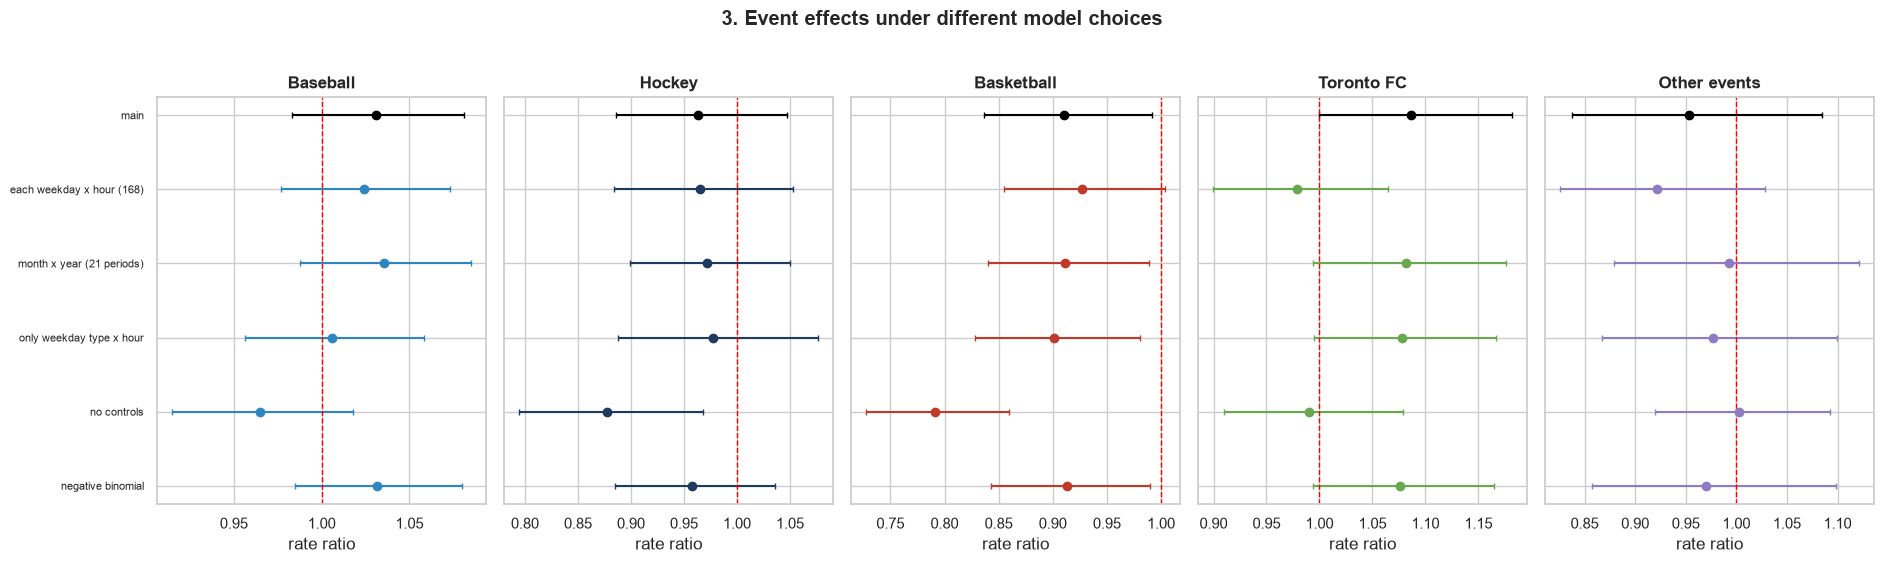

In [6]:
model_variants = {
    "each weekday x hour (168)": RHS_MAIN.replace("C(slot)", "C(weekday_slot)"),
    "month x year (21 periods)": RHS_MAIN.replace("C(month)", "C(period)").replace(" + after_coding_change", ""),  # the period already holds the coding change
    "only weekday type x hour": "C(slot)",
    "no controls": "1",
}
for name, rhs in model_variants.items():
    RESULTS[name] = event_effects(fit_model(main_table, rhs))
RESULTS["negative binomial"] = event_effects(fit_model(main_table, family="negbin"))
model_names = ["main"] + list(model_variants) + ["negative binomial"]
plot_checks(model_names, "3. Event effects under different model choices")
pd.DataFrame({name: RESULTS[name]["rate_ratio"] for name in model_names}).T.round(3)

**How to read it:** the main model with different model choices. The last plot shows each event type under each choice.

**What stands out:**
- **Basketball: 0.90 to 0.93 under every choice that has controls**, and 0.79 with no controls at all. With each weekday × hour (168 groups) it is 0.93 and not clear on its own.
- **Baseball (1.01 to 1.04), hockey (0.96 to 0.98) and other events (0.92 to 0.99) do not change** between choices.
- **Toronto FC is 1.08 with the weekday-type grouping but 0.98 with each weekday separately.** Toronto FC plays almost only on Saturdays, so how Saturday is compared with Sunday decides its answer.
- Without any controls, hockey (0.88) and basketball (0.79) look clearly lower, which shows that the controls matter: they remove part of the apparent dip.
- A negative binomial model, which allows more variation, gives the same answers.

**What it means:** the results do not depend on the distribution or on the controls, with one exception: Toronto FC.

## 4. Which hours are used
Dropping groups of hours that could drive the result. The model is refitted on the remaining hours.

rate ratio                                           event hours left                                          
                                           Baseball Hockey Basketball Toronto FC Other events         Baseball Hockey Basketball Toronto FC Other events
main                                          1.031  0.963      0.911      1.087        0.953             1366    506        525        239           93
without Dec to Feb                            1.021  0.946      0.850      1.076        0.947             1366    318        236        239           93
without January 2025                          1.032  0.977      0.897      1.084        0.952             1366    448        462        239           93
without public holidays                       1.037  0.974      0.915      1.087        0.952             1332    491        517        239           93
without recent snow (3-day snow <= 2 cm)      1.022  0.954      0.883      1.085        0.948             1357    383        367        224           93
without multi-event days                      1.034  0.963      0.912      1.113        1.090              874    408        461        119           28
2025 only                                     1.045  0.940      0.895      1.041        0.991              720    373        327        135           33
2026 only                                     1.019  1.044      0.910      1.117        0.973              646    133        198        104           60
weekdays only                                 1.020  0.908      0.947      1.036        0.903              866    351        381         48           35
weekends only                                 1.035  1.106      0.811      1.124        0.973              500    155        144        191           58
17:00 to 23:59 only                           1.004  0.972      0.950      1.084        1.050              913    473        441        146           53

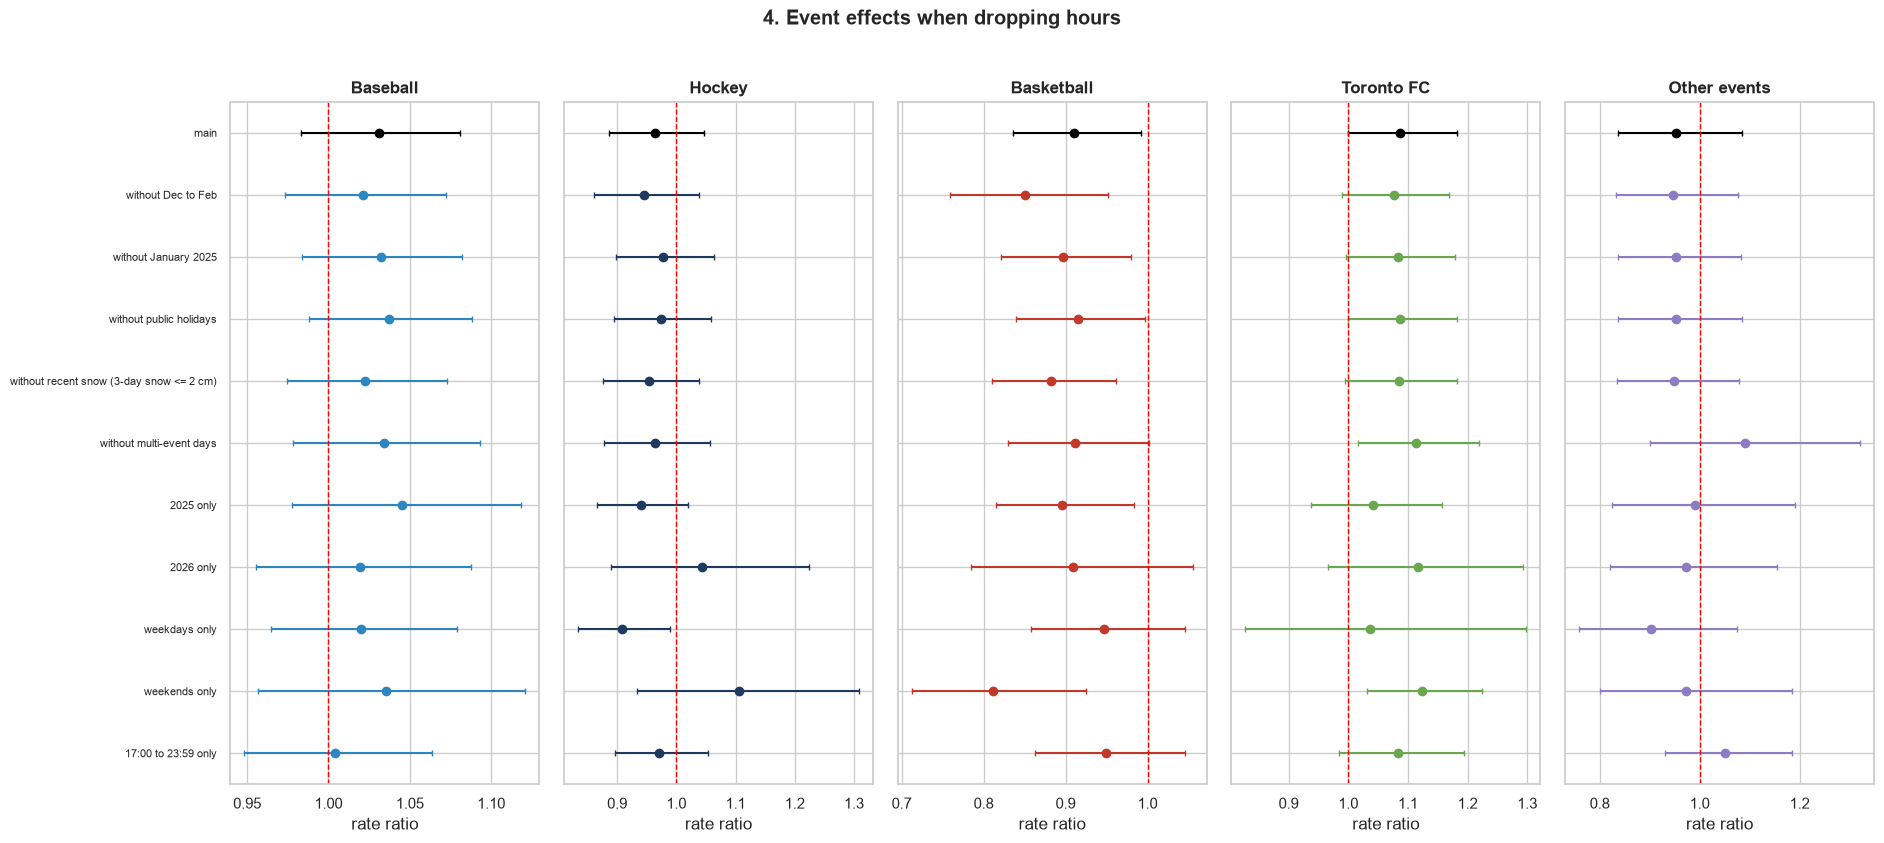

In [7]:
t = main_table
subsets = {
    "without Dec to Feb": ~t["month"].isin([12, 1, 2]),
    "without January 2025": ~((t["year"] == 2025) & (t["month"] == 1)),
    "without public holidays": t["is_holiday"] == 0,
    "without recent snow (3-day snow <= 2 cm)": ~t["snowy"],
    "without multi-event days": t["multi_event_day"] == 0,
    "2025 only": t["year"] == 2025,
    "2026 only": t["year"] == 2026,
    "weekdays only": t["weekday_type"] == "weekday",
    "weekends only": t["weekday_type"] == "weekend",
    "17:00 to 23:59 only": t["hour"].between(17, 23),
}
# in 2026 every month from April on is "after the coding change", so the two controls overlap and the coding flag is left out there
rhs_override = {"2026 only": RHS_MAIN.replace(" + after_coding_change", "")}
for name, mask in subsets.items():
    RESULTS[name] = event_effects(fit_model(t[mask], rhs_override.get(name, RHS_MAIN)))
subset_names = ["main"] + list(subsets)
event_hours_left = pd.DataFrame({name: [int(t.loc[mask if name != "main" else slice(None), c].sum()) for c in EVENT_FLAGS] for name, mask in [("main", None)] + list(subsets.items())},
                                index=EVENT_FLAGS.values()).T
plot_checks(subset_names, "4. Event effects when dropping hours")
pd.concat({"rate ratio": pd.DataFrame({name: RESULTS[name]["rate_ratio"] for name in subset_names}).T.round(3), "event hours left": event_hours_left}, axis=1)

**How to read it:** each row removes one kind of hour and re-fits the model. The right-hand block shows how many event hours are left.

**What stands out:**
- **Basketball: 0.81 to 0.95** in all ten versions. It is **stronger without winter (0.85) and on weekends (0.81)**, and weaker, not clear, on weekdays (0.95) and from 5 pm only (0.95). The dip is **not a winter effect.**
- **Baseball: 1.00 to 1.05** in every version, never clear.
- **Hockey is inconsistent**: 0.94 in 2025 and 1.04 in 2026, 0.91 on weekdays and 1.11 on weekends. It has no stable effect.
- **Toronto FC is above 1 in every case, but only by 1.04 to 1.12**, and it has few hours in some cases (only 48 on weekdays).
- **Other events:** 0.90 to 1.09 with 28 to 93 hours, no stable direction.

**What it means:** dropping winter, January 2025, holidays, snow days or multi-event days never creates an increase for any event type.

## 5. Fake events
Every real event is moved to a **random day with no event and the same weekday**, keeping its hours. The model is refitted (200 times) with the fake events. If events did nothing, the real effects should look like the fake ones.

200 refits in 23 s


,real,fake mean,fake 2.5%,fake 97.5%,share of fake as far from 1
group,,,,,
Baseball,1.031,1.006,0.965,1.062,0.215
Hockey,0.963,1.017,0.933,1.101,0.370
Basketball,0.911,0.988,0.923,1.062,0.000
Toronto FC,1.087,1.113,1.004,1.242,0.635
Other events,0.953,1.010,0.862,1.172,0.525


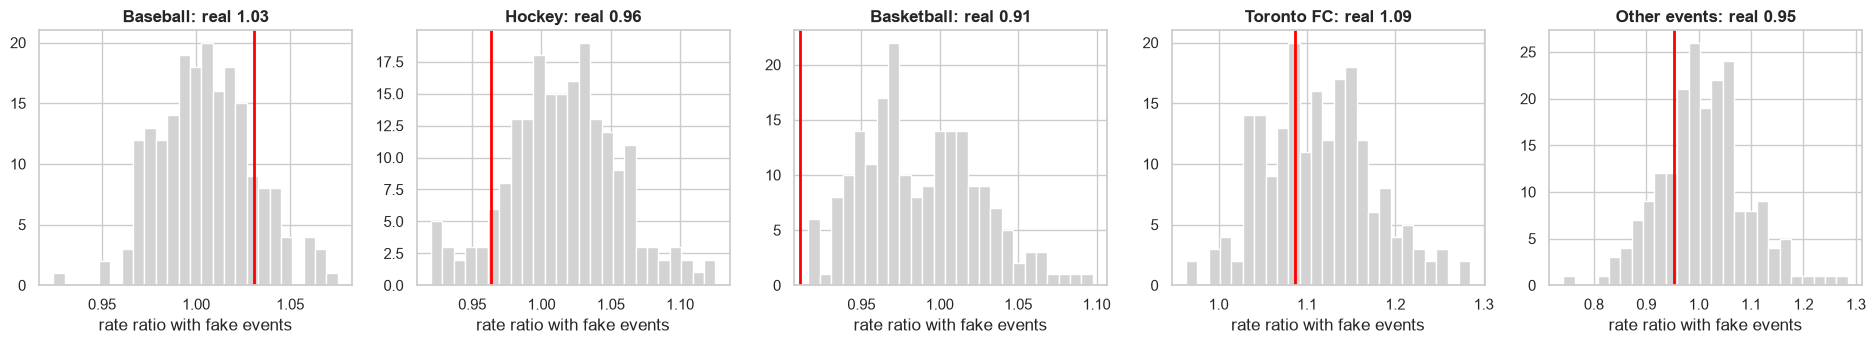

In [8]:
import time

wh = window_hours()
wh = wh.merge(timed[["event_id", "start"]], on="event_id")
wh["base_date"] = wh["start"].dt.normalize()
wh["offset_h"] = ((wh["datetime"] - wh["base_date"]) / pd.Timedelta(hours=1)).astype(int)
event_list = wh.drop_duplicates("event_id")[["event_id", "base_date", "group"]].reset_index(drop=True)
event_list["weekday"] = event_list["base_date"].dt.day_of_week
event_pos = event_list.reset_index().set_index("event_id")["index"]
hour_event = wh["event_id"].map(event_pos).to_numpy()
hour_offset = wh["offset_h"].to_numpy().astype("timedelta64[h]")
hour_group = wh["group"].map(lambda g: f"win_{g}").to_numpy()

times = pd.DatetimeIndex(main_table["datetime"])
real_window = main_table["in_event_window"].to_numpy().astype(bool)
busy_days = set(main_table.loc[main_table["in_event_window"] == 1, "evening_date"])
free_days = pd.Series(sorted(set(main_table["evening_date"]) - busy_days))
by_weekday = [free_days[free_days.dt.day_of_week == k].to_numpy() for k in range(7)]
width = max(len(a) for a in by_weekday)
candidates = np.full((7, width), np.datetime64("NaT", "ns"), dtype="datetime64[ns]")
lengths = np.array([len(a) for a in by_weekday])
for k, a in enumerate(by_weekday):
    candidates[k, :len(a)] = a
weekday_codes = event_list["weekday"].to_numpy()


def fake_events_effects(rng):
    pick = (rng.random(len(event_list)) * lengths[weekday_codes]).astype(int)
    target = candidates[weekday_codes, pick][hour_event] + hour_offset
    pos = times.get_indexer(pd.DatetimeIndex(target))
    ok = pos >= 0
    ok[ok] = ~real_window[pos[ok]]
    data = main_table.copy()
    for col in EVENT_FLAGS:
        data[col] = 0
    for col in EVENT_FLAGS:
        sel = ok & (hour_group == col)
        data.loc[data.index[pos[sel]], col] = 1
    return np.exp(fit_model(data).params[list(EVENT_FLAGS)].to_numpy())


rng = np.random.default_rng(5)
start = time.time()
fake_rr = np.array([fake_events_effects(rng) for _ in range(200)])
print(f"200 refits in {time.time() - start:.0f} s")

real_rr = main_effects["rate_ratio"].to_numpy()
fig, axes = plt.subplots(1, 5, figsize=(19, 3.6))
rows = []
for i, (ax, name) in enumerate(zip(axes, EVENT_FLAGS.values())):
    ax.hist(fake_rr[:, i], bins=25, color="lightgray")
    ax.axvline(real_rr[i], color="red", lw=2)
    ax.set(title=f"{name}: real {real_rr[i]:.2f}", xlabel="rate ratio with fake events")
    rows.append({"group": name, "real": real_rr[i], "fake mean": fake_rr[:, i].mean(), "fake 2.5%": np.percentile(fake_rr[:, i], 2.5),
                 "fake 97.5%": np.percentile(fake_rr[:, i], 97.5), "share of fake as far from 1": (np.abs(np.log(fake_rr[:, i])) >= abs(np.log(real_rr[i]))).mean()})
plt.tight_layout()
placebo = pd.DataFrame(rows).set_index("group")
placebo.round(3)

**How to read it:** the histograms are the effects that **fake events** give: every real event moved to a random day with no event and the same weekday, 200 times, with the full model re-fitted. The red line is the real effect. The table shows the real effect, the fake range, and the share of fake runs as far from 1 as the real one.

**What stands out:**
- **Basketball: real 0.911, fake range 0.923 to 1.062, and none of the 200 fake runs is as far from 1.** It is the only event type that is clearly different from chance.
- **Baseball (22% of fake runs as far from 1), hockey (37%), Toronto FC (64%) and other events (53%) all fall within what chance gives.**
- **Toronto FC's fake events average 1.11**, higher than the real 1.087. Fake Saturday events give the same rise, so the +9% comes from how Saturdays compare with the weekend average and not from the event.

**What it means:** this is the strongest test in this notebook. It confirms basketball and **explains away the Toronto FC rise.**

## 6. Summary of the checks

,lowest,highest,main,checks with interval excluding 1,checks in total
Baseball,0.965,1.045,1.031,0,21
Hockey,0.877,1.106,0.963,2,21
Basketball,0.791,0.950,0.911,15,21
Toronto FC,0.978,1.124,1.087,5,21
Other events,0.903,1.090,0.953,0,21


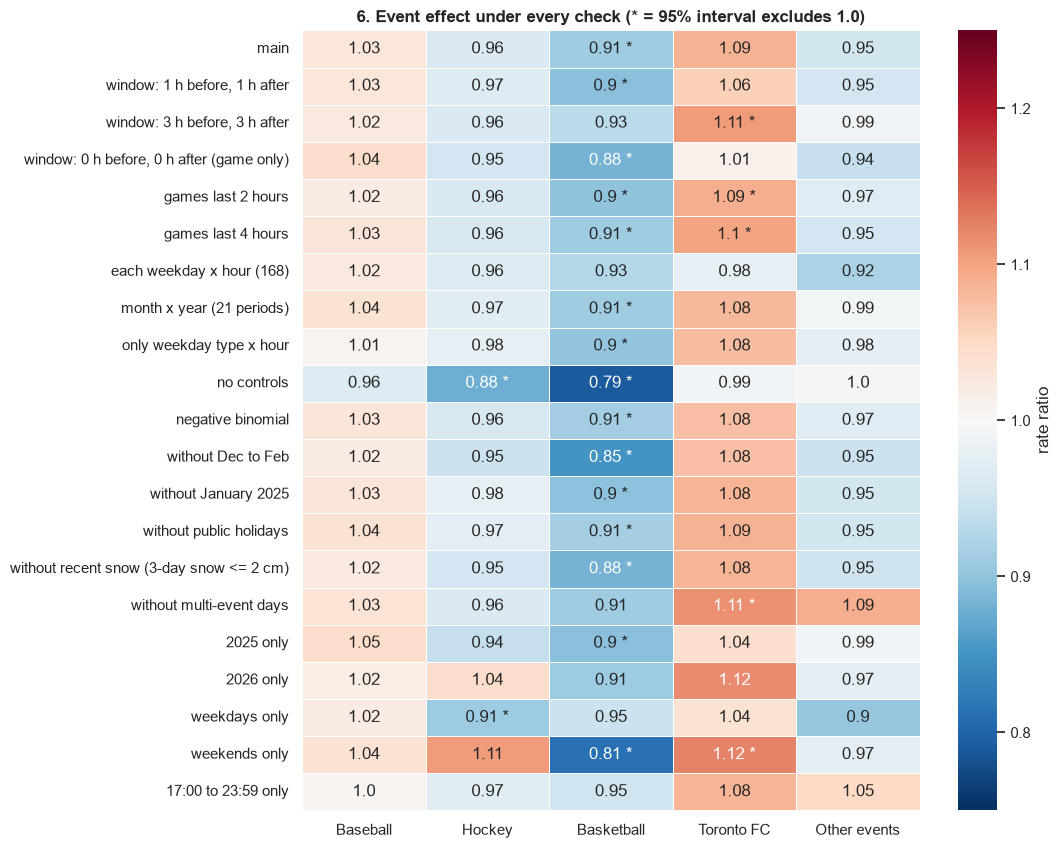

In [9]:
check_order = ["main"] + list(window_variants) + model_names[1:] + list(subsets)
summary_ratio = pd.DataFrame({name: RESULTS[name]["rate_ratio"] for name in check_order}).T
summary_clear = pd.DataFrame({name: (RESULTS[name]["lo"] > 1) | (RESULTS[name]["hi"] < 1) for name in check_order}).T
fig, ax = plt.subplots(figsize=(11, 0.34 * len(check_order) + 1.5))
labels = summary_ratio.round(2).astype(str) + np.where(summary_clear, " *", "")
sns.heatmap(summary_ratio, annot=labels, fmt="", cmap="RdBu_r", center=1, vmin=0.75, vmax=1.25, linewidths=0.4, ax=ax, cbar_kws={"label": "rate ratio"})
ax.set(title="6. Event effect under every check (* = 95% interval excludes 1.0)", ylabel="")
plt.tight_layout()
scorecard = pd.DataFrame({
    "lowest": summary_ratio.min(), "highest": summary_ratio.max(), "main": main_effects["rate_ratio"],
    "checks with interval excluding 1": summary_clear.sum(), "checks in total": len(check_order),
})
scorecard.round(3)

**How to read it:** all 21 checks in one picture. Rows are checks and columns are event types. A star means the 95% interval excludes 1.0. The table counts them.

**What stands out:**

| Event type | Lowest | Highest | Checks with interval excluding 1 (of 21) |
|---|---|---|---|
| Baseball | 0.97 | 1.05 | 0 |
| Hockey | 0.88 | 1.11 | 2 |
| **Basketball** | **0.79** | **0.95** | **15** |
| Toronto FC | 0.98 | 1.12 | 5 |
| Other events | 0.90 | 1.09 | 0 |

- **Basketball is below 1 in all 21 checks**, never above 0.95, and clear in 15.
- **Baseball and other events are never clear.**
- **Hockey's two clear cases** are the no-controls model (0.88) and weekdays only (0.91). The same check on weekends gives 1.11, so it points both ways.
- **Toronto FC's five clear cases** are all above 1 and all use the weekday-type grouping, which the fake-event test shows adds about +11% to any Saturday.

### Verdict
- **Holds:** **no event type raises incidents.** Baseball (0.97 to 1.05) and other events (0.90 to 1.09) are never clearly different from 1 in 21 checks, and hockey changes direction between checks.
- **Holds:** **basketball hours have about 9% fewer incidents** (0.79 to 0.95 across all checks, 15 clear, fake events never as low). It is not a winter, window or model effect.
- **Does not hold:** **the Toronto FC rise (1.09).** It disappears with each weekday matched separately (0.98) and fake Saturday events give the same rise.
- **Not tested here, but from notebook 03:** the near-venue rise for city events rests on 12 events and is only a lead (fake-event check 4.5% and 14%).

**Overall conclusion:** in 21 months of TTC data, major events in Toronto did not make bus service worse in the hours around them. If anything, basketball games at Scotiabank Arena have fewer incidents than comparable hours.